# Iris Classification and PyTorch Regression Experiments

## Scope

This notebook contains two related but distinct experiments. The first uses
Iris measurements to compare classical classification models. The second
explores neural-network regression on the advertising dataset with PyTorch.

## Classification foundations

For a classifier, the goal is to predict a discrete class rather than a
continuous value. The notebook reports accuracy, a confusion matrix, and a
classification report. The confusion matrix counts actual classes by rows and
predicted classes by columns, making different error types visible.

## Regression foundations

The PyTorch section predicts Sales and optimises mean-squared error:

$$
\mathrm{MSE}=\frac{1}{m}\sum_{i=1}^{m}(y_i-\hat{y}_i)^2
$$

The optimiser uses the gradient of this loss to update neural-network weights.
The device selection includes a CPU fallback so the notebook can run without a
CUDA-capable GPU.


In [74]:
import pandas as pd
import  numpy as np
import matplotlib.pyplot as plt

# crosstab

In [20]:
import pandas as pd

# Define the classic Iris column names
column_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']

# Load the dataset using the correct file path
iris = pd.read_csv('data/iris.data', names=column_names)

# Display the first few rows to verify
display(iris.head())

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [21]:
iris

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


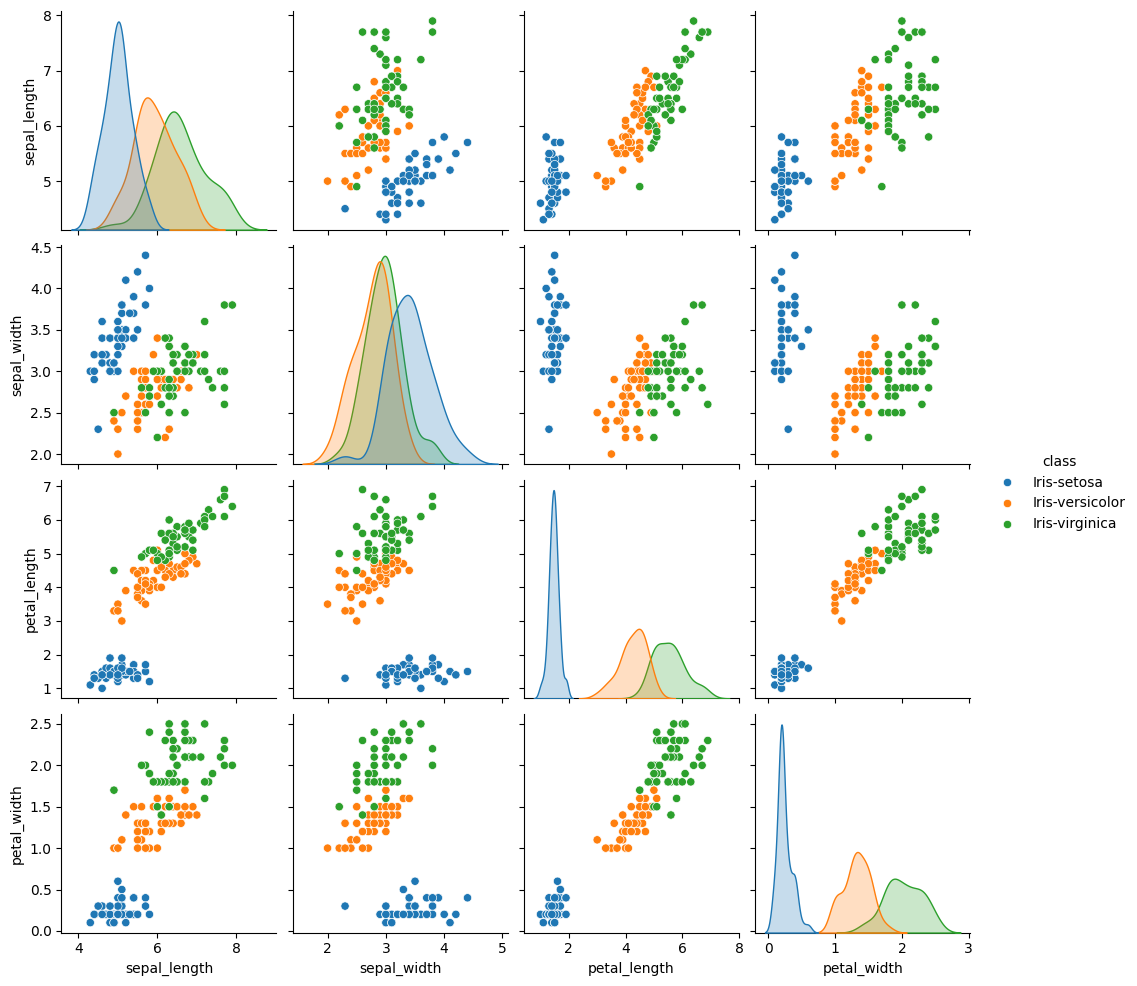

In [22]:
import seaborn as sns
sns.pairplot(iris, hue='class')
plt.show()

In [23]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   class         150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [24]:
iris.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.054000,0.433594,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758667,1.764420,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.198667,0.763161,0.1,0.3,1.30,1.8,2.5


In [25]:
iris.groupby('class').count()

,sepal_length,sepal_width,petal_length,petal_width
class,,,,
Iris-setosa,50,50,50,50
Iris-versicolor,50,50,50,50
Iris-virginica,50,50,50,50


**la data set est equlibre **


/tmp/ipykernel_1603/1998480504.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  bar.set_xticklabels(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'])


[Text(0, 0, 'Iris-setosa'),
 Text(1, 0, 'Iris-versicolor'),
 Text(2, 0, 'Iris-virginica')]

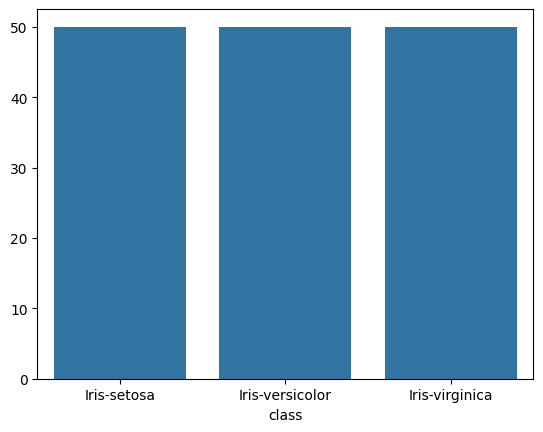

In [26]:
bar = sns.barplot(iris.groupby('class').size())
bar.set_xticklabels(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'])

In [27]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
iris['class'] = le.fit_transform(iris['class'])
iris["class"]

,class
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


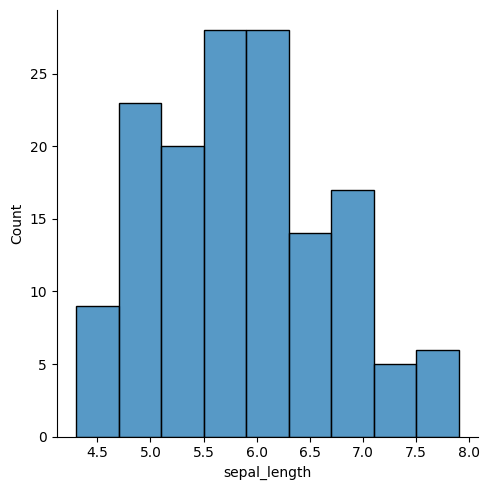

In [28]:
sns.displot(iris.iloc[:,0])

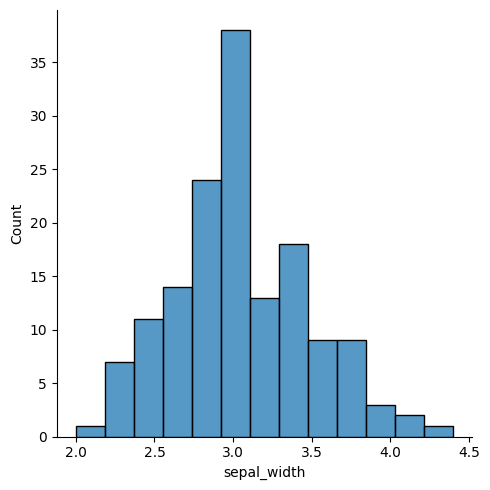

In [29]:
sns.displot(iris.iloc[:,1])

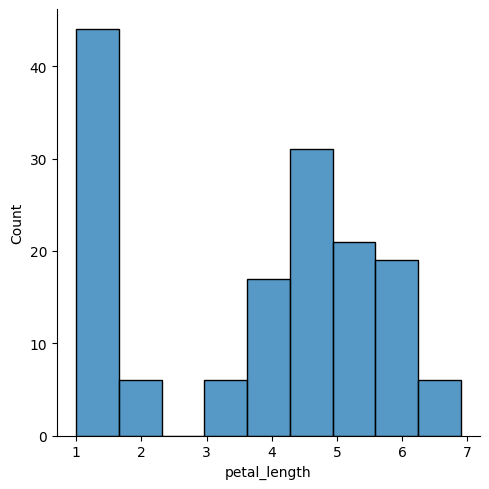

In [30]:
sns.displot(iris.iloc[:,2])

In [31]:
y = iris['class']
X = iris.drop('class', axis=1)
#

In [32]:
y

,class
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


In [33]:
X

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


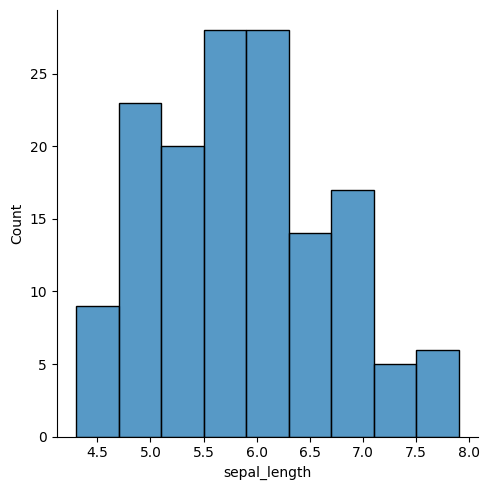

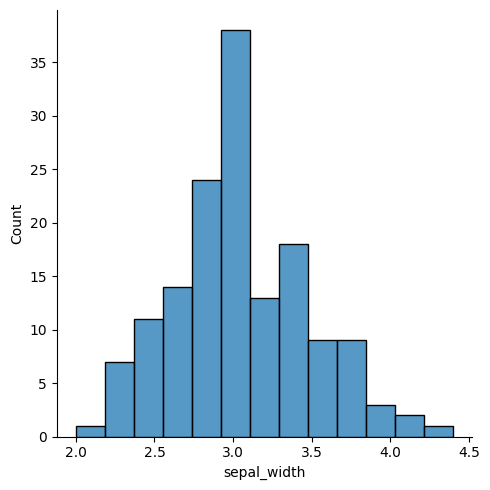

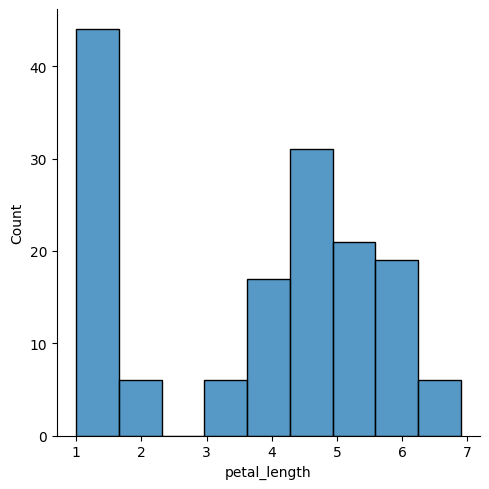

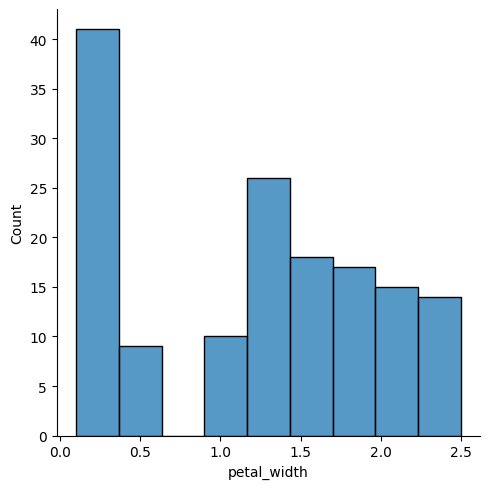

In [34]:
columns  = X.columns
for c in columns :
  sns.displot(X[c])
  plt.show()

<Axes: >

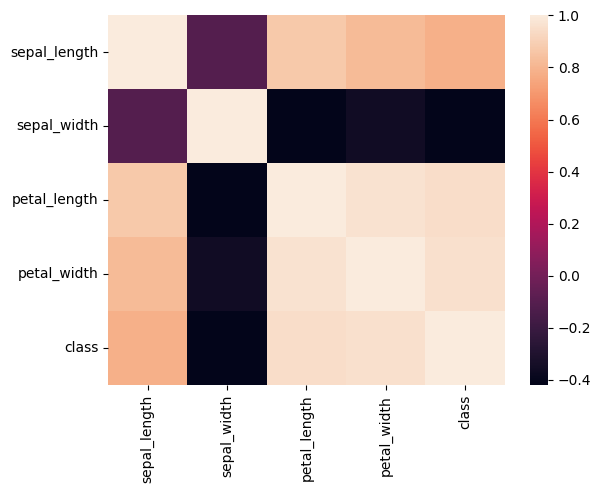

In [35]:
sns.heatmap(iris.corr())

In [36]:
from sklearn.linear_model import LogisticRegression

In [37]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)

In [38]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [39]:
model.score(X_train, y_train)

0.9714285714285714

In [40]:
model.score(X_test, y_test)

0.9333333333333333

<Axes: >

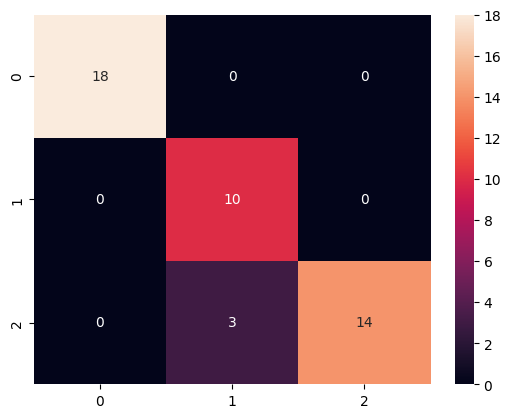

In [41]:
from sklearn.metrics import confusion_matrix
y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True)

In [42]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       0.77      1.00      0.87        10
           2       1.00      0.82      0.90        17

    accuracy                           0.93        45
   macro avg       0.92      0.94      0.92        45
weighted avg       0.95      0.93      0.93        45



In [43]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)
print(model.score(X_train, y_train))
print(model.score(X_test, y_test))


0.9809523809523809
0.9555555555555556


In [44]:
from sklearn.svm import SVC
model = SVC()
model.fit(X_train, y_train)
print(model.score(X_train, y_train))
print(model.score(X_test, y_test))

0.9714285714285714
0.9111111111111111


In [45]:
from sklearn.neural_network import MLPClassifier
model = MLPClassifier(hidden_layer_sizes=(100, 100, 100  , 20 ), max_iter=10000 )
model.fit(X_train, y_train)
print(model.score(X_train, y_train))
print(model.score(X_test, y_test))

0.9904761904761905
0.9333333333333333


In [46]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier()
model.fit(X_train, y_train)
print(model.score(X_train, y_train))
print(model.score(X_test, y_test))

1.0
0.9333333333333333


In [47]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier()
model.fit(X_train, y_train)
print(model.score(X_train, y_train))
print(model.score(X_test, y_test))

1.0
0.9333333333333333


In [48]:
!pip install torch

In [49]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [50]:
torch.__version__

'2.11.0+cu130'

In [51]:
torch.cuda.is_available()

True

In [52]:
df = pd.read_csv("data/Advertising.csv")

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [54]:
import seaborn as sns

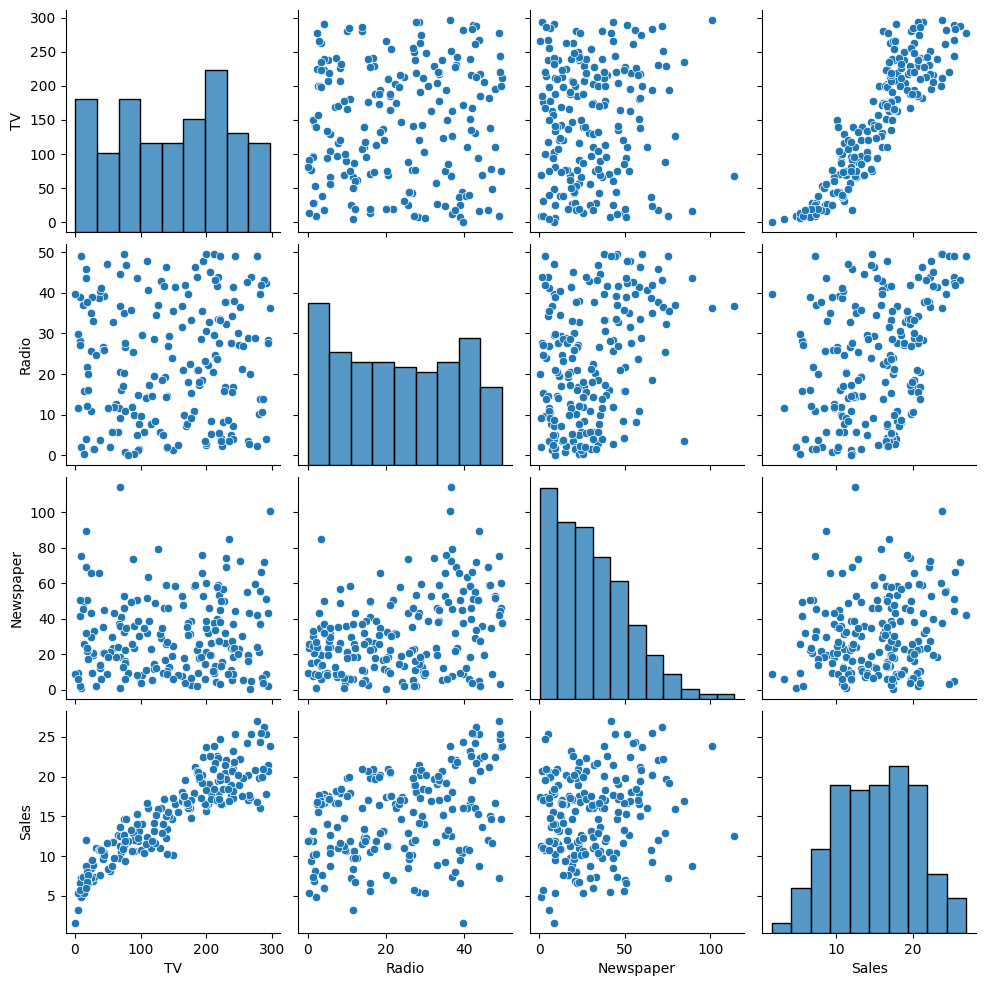

In [55]:
sns.pairplot(data  = df )

In [56]:
df.dropna(inplace=True , how = "any")

In [57]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
TV,200.0,147.0425,85.854236,0.7,74.375,149.75,218.825,296.4
Radio,200.0,23.2640,14.846809,0.0,9.975,22.90,36.525,49.6
Newspaper,200.0,30.5540,21.778621,0.3,12.750,25.75,45.100,114.0
Sales,200.0,15.1305,5.283892,1.6,11.000,16.00,19.050,27.0


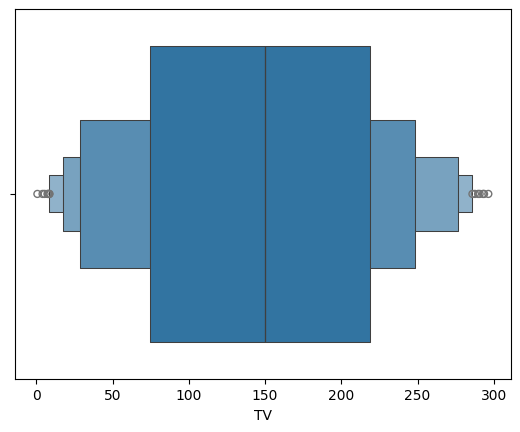

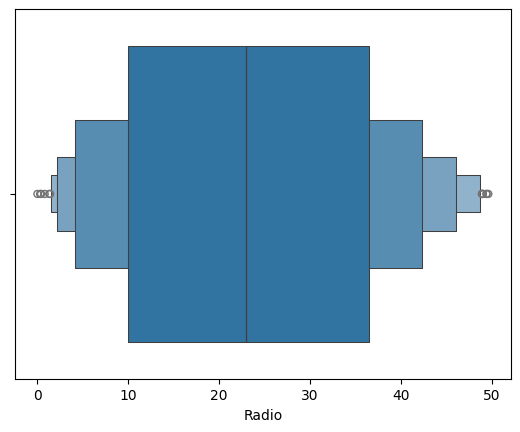

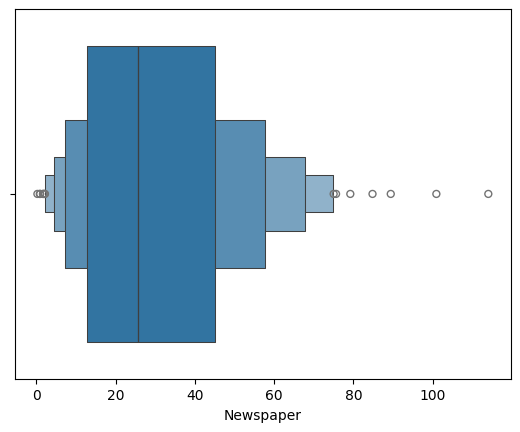

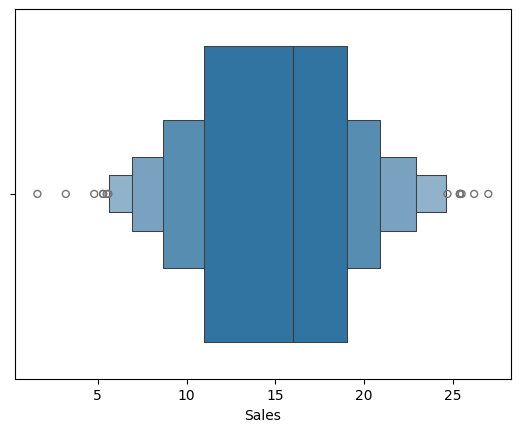

In [58]:
for c in df.columns :
  sns.boxenplot(data = df , x = c)
  plt.show()

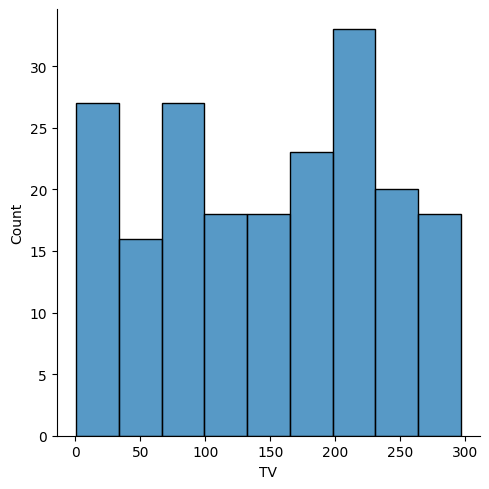

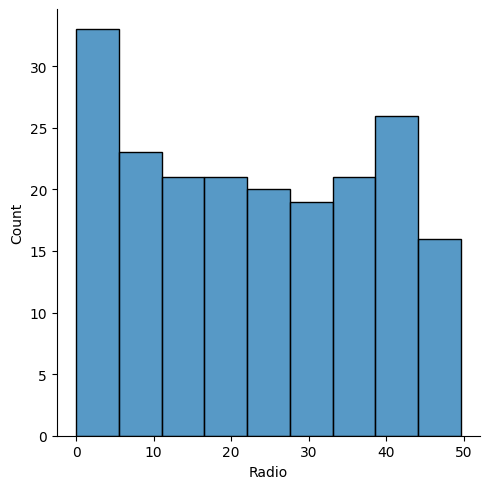

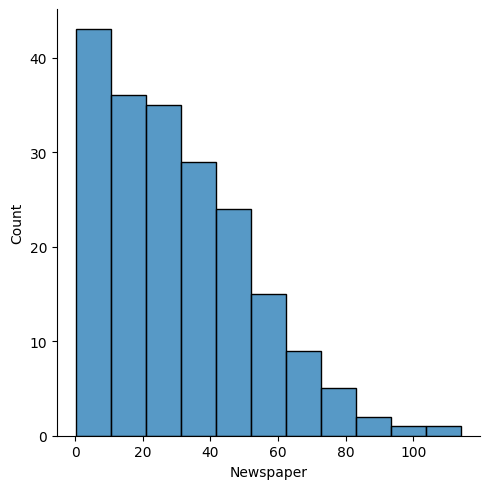

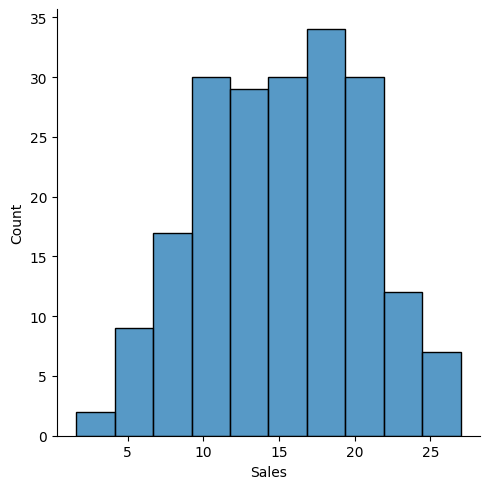

In [59]:
for c in df.columns :
  sns.displot(data = df , x = c)
  plt.show()

In [60]:
X = df.drop("Sales" , axis=1).values
y = df["Sales"].values

In [61]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [62]:
X_train

array([[193.2,  18.4,  65.7],
       [287.6,  43. ,  71.8],
       [ 80.2,   0. ,   9.2],
       [182.6,  46.2,  58.7],
       [222.4,   4.3,  49.8],
       [250.9,  36.5,  72.3],
       [187.8,  21.1,   9.5],
       [ 78.2,  46.8,  34.5],
       [125.7,  36.9,  79.2],
       [131.1,  42.8,  28.9],
       [234.5,   3.4,  84.8],
       [ 62.3,  12.6,  18.3],
       [286. ,  13.9,   3.7],
       [ 76.4,   0.8,  14.8],
       [ 97.5,   7.6,   7.2],
       [216.4,  41.7,  39.6],
       [ 85.7,  35.8,  49.3],
       [243.2,  49. ,  44.3],
       [  7.3,  28.1,  41.4],
       [232.1,   8.6,   8.7],
       [280.7,  13.9,  37. ],
       [131.7,  18.4,  34.6],
       [ 56.2,   5.7,  29.7],
       [205. ,  45.1,  19.6],
       [166.8,  42. ,   3.6],
       [240.1,  16.7,  22.9],
       [ 17.2,   4.1,  31.6],
       [206.8,   5.2,  19.4],
       [238.2,  34.3,   5.3],
       [177. ,   9.3,   6.4],
       [ 28.6,   1.5,  33. ],
       [237.4,   5.1,  23.5],
       [ 48.3,  47. ,   8.5],
       [ 7

In [63]:
device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [64]:
X_train = torch.tensor(X_train).to(device)
y_train = torch.tensor(y_train).to(device)

In [65]:
X_test = torch.tensor(X_test).to(device)
y_test = torch.tensor(y_test).to(device)

In [66]:
X_train

tensor([[193.2000,  18.4000,  65.7000],
        [287.6000,  43.0000,  71.8000],
        [ 80.2000,   0.0000,   9.2000],
        [182.6000,  46.2000,  58.7000],
        [222.4000,   4.3000,  49.8000],
        [250.9000,  36.5000,  72.3000],
        [187.8000,  21.1000,   9.5000],
        [ 78.2000,  46.8000,  34.5000],
        [125.7000,  36.9000,  79.2000],
        [131.1000,  42.8000,  28.9000],
        [234.5000,   3.4000,  84.8000],
        [ 62.3000,  12.6000,  18.3000],
        [286.0000,  13.9000,   3.7000],
        [ 76.4000,   0.8000,  14.8000],
        [ 97.5000,   7.6000,   7.2000],
        [216.4000,  41.7000,  39.6000],
        [ 85.7000,  35.8000,  49.3000],
        [243.2000,  49.0000,  44.3000],
        [  7.3000,  28.1000,  41.4000],
        [232.1000,   8.6000,   8.7000],
        [280.7000,  13.9000,  37.0000],
        [131.7000,  18.4000,  34.6000],
        [ 56.2000,   5.7000,  29.7000],
        [205.0000,  45.1000,  19.6000],
        [166.8000,  42.0000,   3.6000],


In [67]:
X_train.dtype

torch.float64

In [68]:
X_train = X_train.float().to(device)
y_train = y_train.float().to(device)

In [69]:
import torch.nn as nn

In [70]:
class Model(nn.Module):
  def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(3   ,20)
        self.relu = nn.ReLU()
        self.layer2 = nn.Linear(20   ,10)
        self.relu = nn.ReLU()
        self.layer3 = nn.Linear(10   ,1)

  def forward(self  , x):
          x = self.layer1(x)
          x = self.relu(x)
          x = self.layer2(x)
          x = self.relu(x)
          x = self.layer3(x)
          return x


In [71]:
model = Model().float().to(device)
loss_function = nn.MSELoss().to(device)
optmazer = torch.optim.Adam(model.parameters() , lr=0.01)

In [72]:
epochs = 100000
# Reshape y_train to (140, 1) to match model output shape
y_train_reshaped = y_train.unsqueeze(1)

for e in range(epochs):
  y_pred = model(X_train)
  loss = loss_function(y_pred, y_train_reshaped)
  optmazer.zero_grad()
  loss.backward()
  optmazer.step()
  if e % 1000 == 0:
    print(f"epoch : {e}  ,  loss =  {loss.item()}")

epoch : 0  ,  loss =  1368.264404296875
epoch : 1000  ,  loss =  1.6364578008651733
epoch : 2000  ,  loss =  1.1211745738983154
epoch : 3000  ,  loss =  1.0163594484329224
epoch : 4000  ,  loss =  0.8891324996948242
epoch : 5000  ,  loss =  0.8267599940299988
epoch : 6000  ,  loss =  0.7995156049728394
epoch : 7000  ,  loss =  0.7861325740814209
epoch : 8000  ,  loss =  0.805804431438446
epoch : 9000  ,  loss =  0.7507113814353943
epoch : 10000  ,  loss =  0.841494619846344
epoch : 11000  ,  loss =  0.6585894227027893
epoch : 12000  ,  loss =  0.7600539922714233
epoch : 13000  ,  loss =  0.5738460421562195
epoch : 14000  ,  loss =  0.6040308475494385
epoch : 15000  ,  loss =  0.5503215193748474
epoch : 16000  ,  loss =  0.6102489829063416
epoch : 17000  ,  loss =  0.6720053553581238
epoch : 18000  ,  loss =  0.6749492287635803
epoch : 19000  ,  loss =  0.5730897188186646
epoch : 20000  ,  loss =  0.5107427835464478
epoch : 21000  ,  loss =  0.5949967503547668
epoch : 22000  ,  loss =  

In [73]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

model.eval()

with torch.no_grad():
    y_pred = model(X_test.float())

# Convert tensors to NumPy arrays
y_pred = y_pred.cpu().numpy().ravel()
y_true = y_test.cpu().numpy().ravel()

# Calculate metrics
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_true, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("RÂ² Score:", r2)

MAE: 0.9972012662887574
MSE: 1.9882399316194523
RMSE: 1.4100496202685395
RÂ² Score: 0.9287931467712022
